### Célula 0 — Setup e conexão

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from databricks import sql

load_dotenv()

# Parâmetro do pipeline — "store" ou "warehouse".
# Trocar aqui e reexecutar o notebook do início é o que gera a segunda passagem (Centro de Distribuição),
# sem duplicar nenhuma lógica de query.
LOCATION_TYPE = "warehouse"   # trocar para "warehouse" na segunda execução

connection = sql.connect(
    server_hostname=os.environ["DATABRICKS_HOST"],
    http_path=os.environ["DATABRICKS_HTTP_PATH"],
    access_token=os.environ["DATABRICKS_TOKEN"],
    catalog=os.environ.get("DATABRICKS_CATALOG", "dev"),
    schema="gold",
)

def run_query(query: str) -> pd.DataFrame:
    """Executa uma query no SQL Warehouse e retorna um DataFrame pandas."""
    with connection.cursor() as cursor:
        cursor.execute(query)
        if cursor.description is None:
            return pd.DataFrame()
        rows = cursor.fetchall()
        columns = [desc[0] for desc in cursor.description]
        return pd.DataFrame(rows, columns=columns)

### Célula 1 — Base de análise

**O que mudou e por quê:** esta célula antes reagregava `fct_orders` na mão, com os mesmos joins que a mart já faz — o que significava que ela **nunca via a quarentena de dados futuros** aplicada em `fct_demanda_mensal_produto_local.sql` (a quarentena só existe dentro do modelo dbt da mart, de propósito, para não afetar Power BI/outros consumidores de `fct_orders`). Ler direto da mart corrige isso automaticamente, e ainda elimina duplicação de lógica (DRY) — a agregação já está pronta lá.

In [12]:
run_query(f"""
CREATE OR REPLACE TEMP VIEW eda_base AS
SELECT
    product_variant_id,
    product_name,
    category_name,
    location_id,
    location_name,
    ano,
    mes,
    mes_ref,
    quantidade_mes,
    valor_liquido_mes
FROM fct_demanda_mensal_produto_local
WHERE location_type = '{LOCATION_TYPE}'
""")

,Result


### Célula 2 — Volume de vendas por combinação variante×loja

count    3027.000000
mean      125.436736
std        29.454349
min        28.000000
10%        88.000000
25%       105.000000
50%       124.000000
75%       145.000000
90%       164.000000
95%       176.000000
99%       198.000000
max       241.000000
Name: quantidade_total, dtype: float64


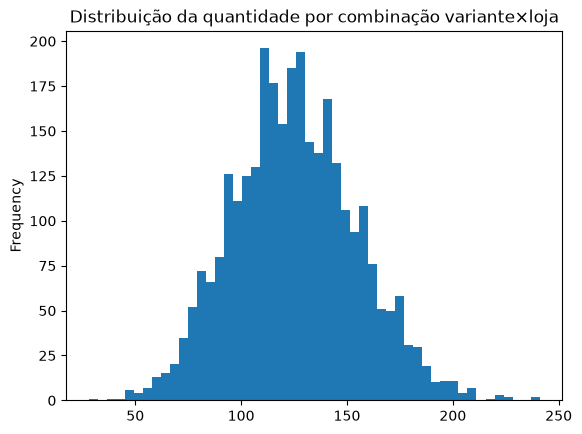

count          3027
unique         3027
top       261986.21
freq              1
Name: valor_total, dtype: object


In [13]:
df_vol = run_query("""
    SELECT product_variant_id, location_id,
           SUM(quantidade_mes)    AS quantidade_total,
           SUM(valor_liquido_mes) AS valor_total
    FROM eda_base
    GROUP BY product_variant_id, location_id
""")

# Métrica principal: quantidade (o que orienta disponibilidade de estoque)
print(df_vol['quantidade_total'].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))
df_vol.sort_values('quantidade_total', ascending=False).head(20)   # top 20 combinações por demanda
df_vol.sort_values('quantidade_total', ascending=True).head(20)    # bottom 20 (candidatas a esparsidade)

df_vol['quantidade_total'].plot(kind='hist', bins=50, title='Distribuição da quantidade por combinação variante×loja')
plt.show()

# Métrica secundária: valor líquido, só como contexto (não usado para ranking nesta EDA)
print(df_vol['valor_total'].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]))

### Célula 3 — Série mensal das combinações de maior volume

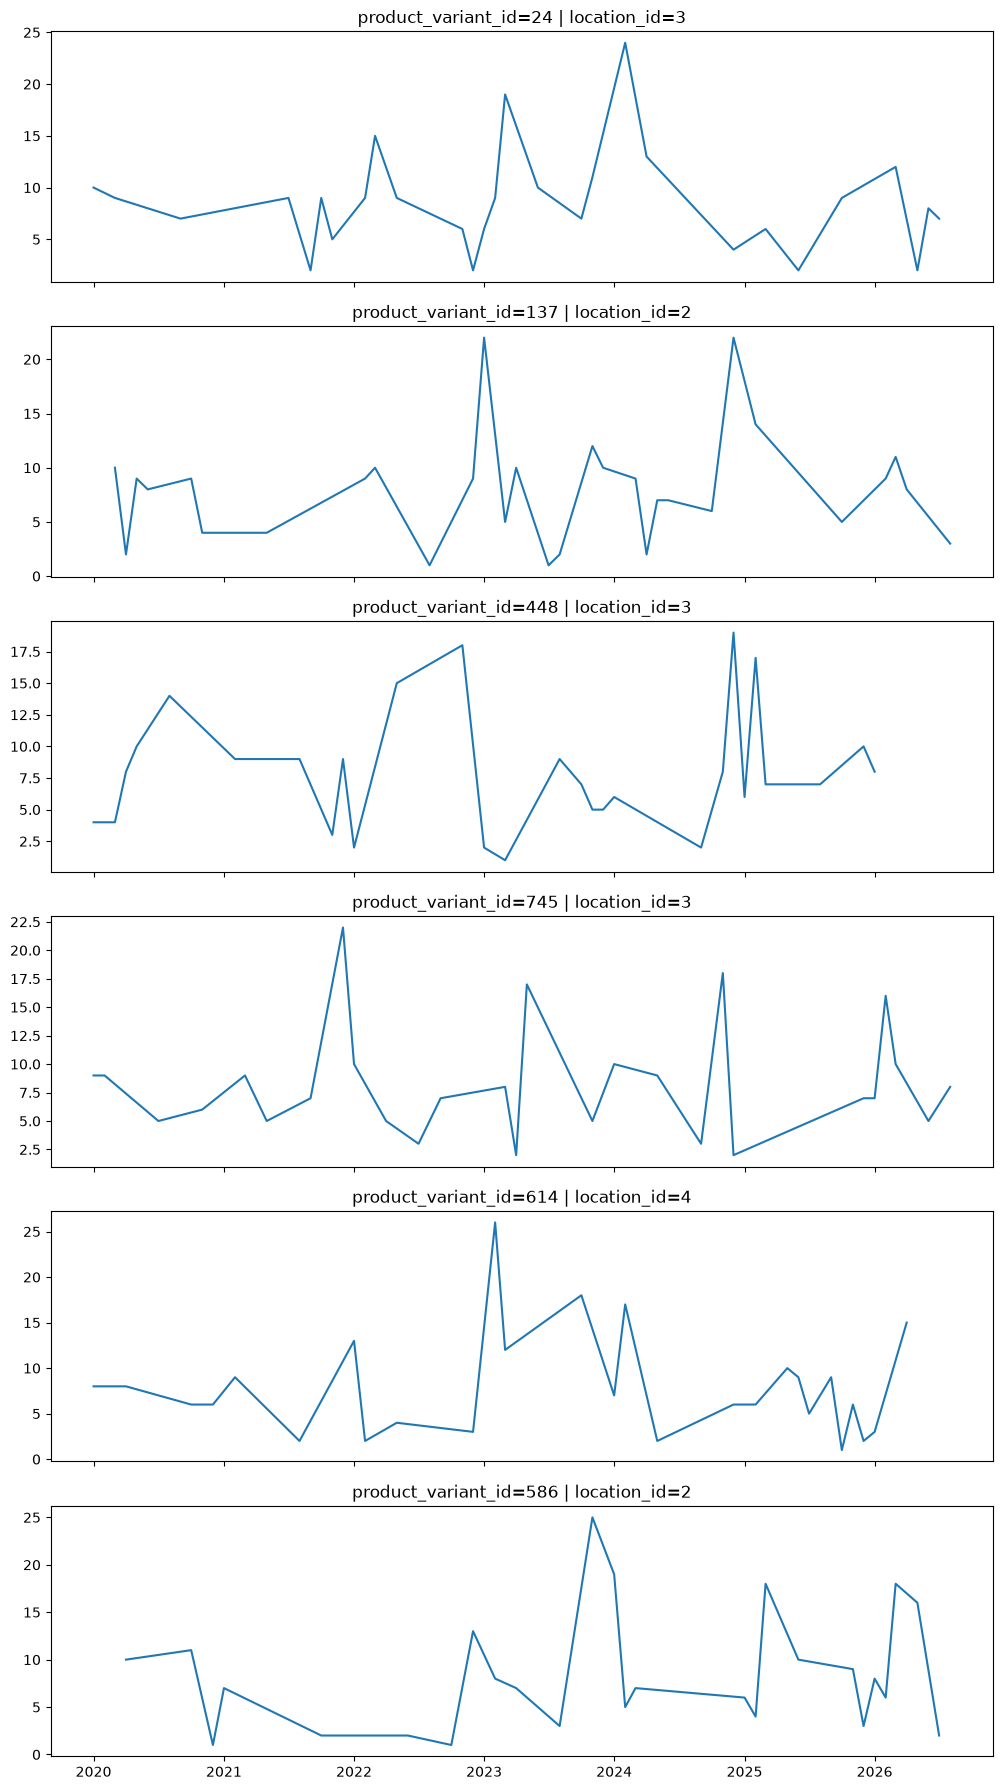

In [14]:
top_combos = df_vol.sort_values('quantidade_total', ascending=False).head(6)[['product_variant_id','location_id']]

df_serie = run_query("""
    SELECT product_variant_id, location_id, mes_ref, quantidade_mes, valor_liquido_mes
    FROM eda_base
""")

fig, axes = plt.subplots(len(top_combos), 1, figsize=(10, 3*len(top_combos)), sharex=True)
for ax, (_, row) in zip(axes, top_combos.iterrows()):
    sub = df_serie[(df_serie.product_variant_id==row.product_variant_id) & (df_serie.location_id==row.location_id)].sort_values('mes_ref')
    ax.plot(sub.mes_ref, sub.quantidade_mes)   # série principal: quantidade
    ax.set_title(f"product_variant_id={row.product_variant_id} | location_id={row.location_id}")
plt.tight_layout()
plt.show()

### Célula 4 — Cobertura de histórico (REFATORADA: lê direto da mart, sem recalcular janela)

**O que mudou e por quê:** antes, esta célula recalculava `meses_com_venda`/`meses_de_vida`/`pct_cobertura` na mão, a partir de `eda_base`. Isso não é mais necessário — a mart **já calcula essas três colunas** (dentro da mesma CTE que aplica a quarentena), então basta ler os valores já prontos, uma linha por combinação. Menos código, e garantidamente sincronizado com o que a mart realmente usa para a flag `historico_suficiente`.

In [ ]:
run_query(f"""
CREATE OR REPLACE TEMP VIEW eda_historico AS
SELECT DISTINCT
    product_variant_id,
    location_id,
    meses_com_venda,
    meses_de_vida,
    (meses_de_vida - meses_com_venda) AS meses_com_demanda_zero,
    pct_cobertura
FROM fct_demanda_mensal_produto_local
WHERE location_type = '{LOCATION_TYPE}'
""")

df_hist = run_query("SELECT * FROM eda_historico")

# Distribuição por faixa de cobertura — insumo direto do limiar "série madura vs. esparsa"
bins = [0, .25, .5, .75, .9, 1.0]
df_hist['faixa_cobertura'] = pd.cut(df_hist['pct_cobertura'], bins=bins, include_lowest=True)
tabela_cobertura = df_hist['faixa_cobertura'].value_counts(normalize=True).sort_index()
print(tabela_cobertura)

# Checagem rápida: a distribuição de meses_de_vida varia entre combinações?
# Se toda combinação tiver o mesmo meses_de_vida (≈ janela do dataset inteiro), é sinal de que
# a maioria dos produtos já existia desde o início do histórico — informação útil por si só.
print(df_hist['meses_de_vida'].describe(percentiles=[.1, .5, .9]))

faixa_cobertura
(-0.001, 0.25]    0.411959
(0.25, 0.5]       0.588041
(0.5, 0.75]       0.000000
(0.75, 0.9]       0.000000
(0.9, 1.0]        0.000000
Name: proportion, dtype: float64
count    3027.000000
mean       72.855633
std         5.597714
min        41.000000
10%        65.000000
50%        74.000000
90%        79.000000
max        80.000000
Name: meses_de_vida, dtype: float64


### Célula 5.1 — Indícios de sazonalidade por categoria

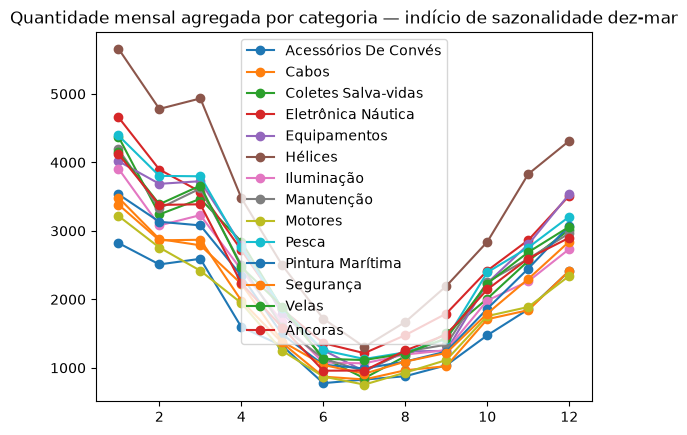

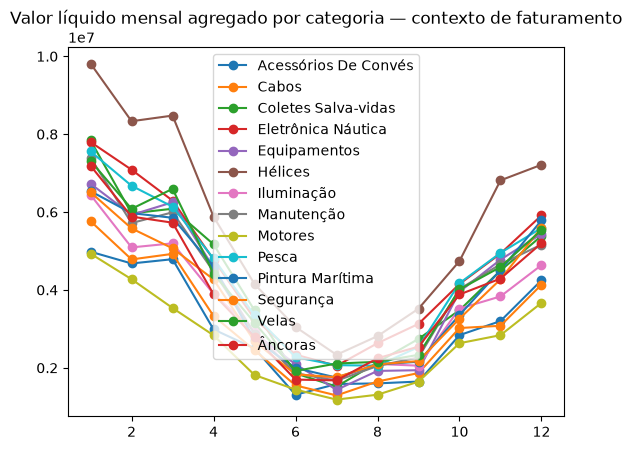

In [16]:
df_cat = run_query("""
    SELECT category_name, mes,
           SUM(quantidade_mes)    AS quantidade_total,
           SUM(valor_liquido_mes) AS valor_total
    FROM eda_base
    GROUP BY category_name, mes
    ORDER BY category_name, mes
""")

# Sazonalidade de demanda: primária por quantidade
for cat in df_cat.category_name.unique():
    sub = df_cat[df_cat.category_name == cat]
    plt.plot(sub.mes, sub.quantidade_total, marker='o', label=cat)
plt.legend(); plt.title("Quantidade mensal agregada por categoria — indício de sazonalidade dez-mar")
plt.show()

# Leitura secundária (contexto de faturamento/ROI, não usada para decidir sazonalidade de demanda)
for cat in df_cat.category_name.unique():
    sub = df_cat[df_cat.category_name == cat]
    plt.plot(sub.mes, sub.valor_total, marker='o', label=cat)
plt.legend(); plt.title("Valor líquido mensal agregado por categoria — contexto de faturamento")
plt.show()

### Célula 5.2 — Candidatas provisórias a sazonalidade (corte de volume, não o limiar oficial)

periodo             alta_temporada  resto_do_ano  indice_sazonalidade
product_variant_id                                                   
763                      12.500000      5.480000             2.281022
3                        15.555556      7.083333             2.196078
965                      13.117647      6.037037             2.172862
682                      12.315789      6.103448             2.017841
137                      13.952381      6.931034             2.013030
272                      12.200000      6.115385             1.994969
769                      13.529412      7.000000             1.932773
279                      13.700000      7.090909             1.932051
797                      11.772727      6.142857             1.916490
735                      13.894737      7.380952             1.882513


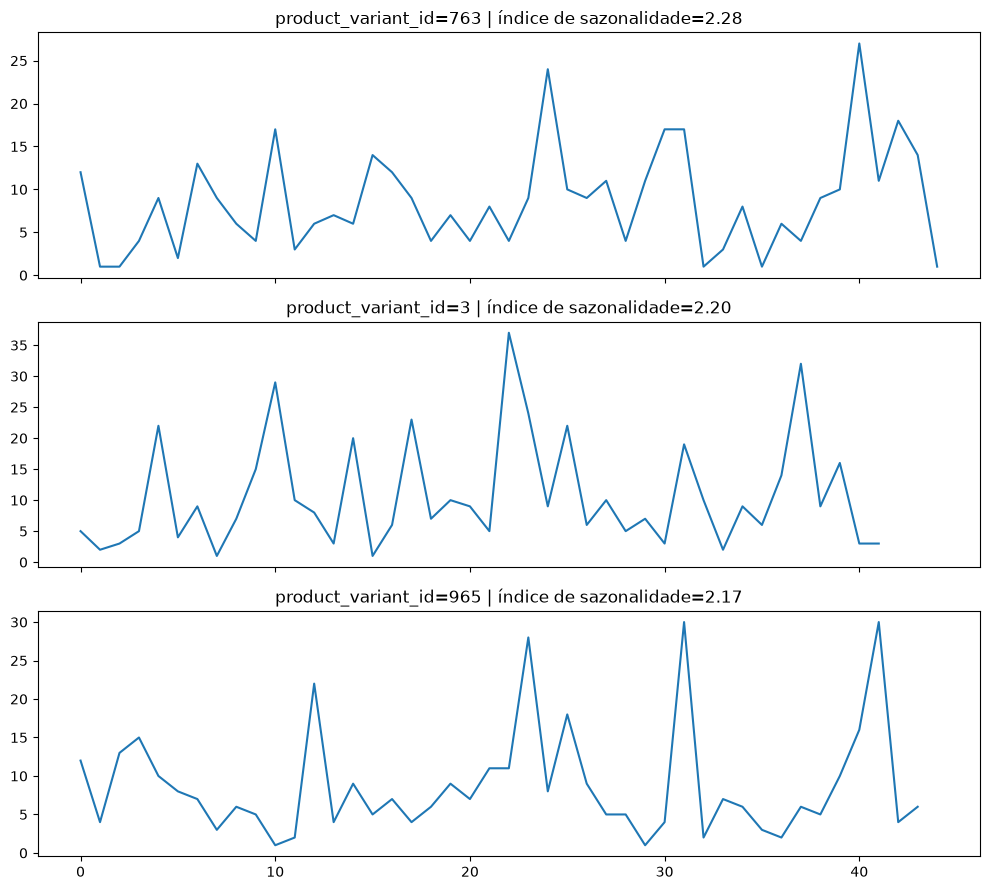

In [ ]:
# 1. Demanda por variante e mês, somando todas as lojas e todos os anos disponíveis
df_variant_month = run_query("""
    SELECT product_variant_id, ano, mes, SUM(quantidade_mes) AS quantidade
    FROM eda_base
    GROUP BY product_variant_id, ano, mes
""")

# 2. Filtrar fora variantes de volume muito baixo (evita indicador de sazonalidade "de ruído")
volume_por_variante = df_vol.groupby('product_variant_id')['quantidade_total'].sum()
limiar_volume_provisorio = volume_por_variante.median()   # provisório, só para esta pré-seleção
variantes_com_volume = volume_por_variante[volume_por_variante >= limiar_volume_provisorio].index
df_variant_month = df_variant_month[df_variant_month.product_variant_id.isin(variantes_com_volume)]

# 3. Indicador de sazonalidade: demanda média em dez/jan/fev/mar vs. demanda média no resto do ano
MESES_ALTA_TEMPORADA = [12, 1, 2, 3]
df_variant_month['periodo'] = df_variant_month['mes'].apply(
    lambda m: 'alta_temporada' if m in MESES_ALTA_TEMPORADA else 'resto_do_ano'
)

medias = (
    df_variant_month
    .groupby(['product_variant_id', 'periodo'])['quantidade']
    .mean()
    .unstack('periodo')
    .dropna()   # descarta variantes sem dado em algum dos dois períodos
)
medias = medias[medias['resto_do_ano'] > 0]   # evita divisão por zero
medias['indice_sazonalidade'] = medias['alta_temporada'] / medias['resto_do_ano']

candidatos_sazonalidade = medias.sort_values('indice_sazonalidade', ascending=False).head(10)
print(candidatos_sazonalidade)

# 4. Inspeção visual das 3 melhores candidatas, para confirmar que o número reflete um padrão real e não um artefato
top3_variantes = candidatos_sazonalidade.head(3).index.tolist()
fig, axes = plt.subplots(len(top3_variantes), 1, figsize=(10, 3*len(top3_variantes)), sharex=True)
for ax, variant_id in zip(axes, top3_variantes):
    sub = df_variant_month[df_variant_month.product_variant_id == variant_id].sort_values(['ano', 'mes'])
    ax.plot(range(len(sub)), sub['quantidade'])
    ax.set_title(f"product_variant_id={variant_id} | índice de sazonalidade={candidatos_sazonalidade.loc[variant_id, 'indice_sazonalidade']:.2f}")
plt.tight_layout()
plt.show()

### Célula 6 — Outliers / distorções na demanda

In [18]:
q99 = df_serie['quantidade_mes'].quantile(0.99)
outliers = df_serie[df_serie['quantidade_mes'] > q99].sort_values('quantidade_mes', ascending=False)
outliers[['product_variant_id','location_id','mes_ref','quantidade_mes','valor_liquido_mes']]

,product_variant_id,location_id,mes_ref,quantidade_mes,valor_liquido_mes
30214,374,2,2025-12-01,39,33017.46
55390,116,4,2025-11-01,37,94177.31
52793,372,4,2026-03-01,36,103105.09
26727,776,3,2024-12-01,36,79308.52
4707,146,3,2026-04-01,33,67430.87
...,...,...,...,...,...
121,774,2,2020-09-01,20,20115.42
55800,319,3,2022-02-01,20,35991.12
106,263,3,2026-03-01,20,55569.63
57619,160,2,2025-03-01,20,16286.50


### Célula 7 — Efeito de feriados/calendário (REFATORADA: agora com o filtro de quarentena aplicado manualmente)

**O que mudou e por quê:** esta célula consulta `fct_orders` **diretamente** (grão diário, que a mart não tem — ela é mensal), então precisa do filtro de quarentena aplicado aqui na mão (`venda_futura = false`), já que não passa pela mart. Sem isso, ela continuaria vendo o dado futuro, mesmo com a Célula 1 corrigida.

In [19]:
run_query("""
    SELECT
        c.feriado,
        c.fim_de_semana,
        AVG(f.valor_liquido_item) AS ticket_medio_dia
    FROM fct_orders f
    JOIN dim_calendar c ON f.placed_at_key = c.date_key
    WHERE f.venda_futura = false
    GROUP BY c.feriado, c.fim_de_semana
""")

,feriado,fim_de_semana,ticket_medio_dia
0,False,True,9540.186418
1,True,True,9554.226251
2,True,False,9773.540294
3,False,False,9537.665211


### Célula 8 — Encerrar a conexão

In [20]:
connection.close()